# Predicting Customer Repeat Purchase Behaviour Using Machine Learning
## 1. Data import and exploration
### 1.1. Introduction and objective
   Everything & Then Some, Ltd. is a diversified wholesale company whose customers exhibit different purchasing behaviours.
  
   The objective of this project is to develop a machine learning model that predicts whether a customer will make another purchase within 90 days after a given transaction.
   
   The first phase focuses on understanding the available datasets, exploring the variables, assessing data quality, and identifying relevant patterns that may help predict repeat-purchase behaviour.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv("data/train.csv", index_col="ID")
test = pd.read_csv("data/test.csv", index_col="ID")
clientes = pd.read_csv("data/clientes.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

print("All files loaded with success!")

All files loaded with success!


In [3]:
# First 5 rows of the train dataset:
train.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [4]:
# Last 5 rows of the train dataset:
train.tail()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10007670,3023.34,3761.38,2458.00,565.34,0.0,0.00,1303.38,1099.190000,49.0,1.0,...,5548.20,151492,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,-1.579719
10007671,1362.26,1723.10,1107.53,254.73,0.0,34.25,581.32,197.514000,16.0,1.0,...,0.00,975873,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,-0.576883
10007672,4396.55,3574.43,3574.43,822.12,0.0,0.00,0.00,2075.838024,78.0,1.0,...,27824.52,755628,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,0.528377
10007673,452.07,483.60,367.54,84.53,0.0,0.00,116.06,265.159468,7.0,1.0,...,12484.20,703834,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2019-03-23,1.012809
10007674,951.71,982.00,773.75,177.96,0.0,0.00,208.25,224.543079,30.0,1.0,...,2256.28,438652,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 3,2019-11-23,-0.041337


In [5]:
train.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

In [6]:
# To keep 3 decimal places without scientific notation (e+)
pd.set_option('display.float_format','{:,.3f}'.format)

In [7]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,"6,469.000",925.556,"1,334.998",0.930,188.920,476.740,"1,087.670","22,297.210"
Total Bruto,"6,469.000",886.153,"1,327.641",0.830,175.740,445.740,"1,036.700","21,578.280"
Total Liquido,"6,469.000",773.336,"1,136.356",0.760,154.380,389.910,903.370,"18,127.810"
Total Imp_,"6,469.000",152.220,225.262,0.000,29.930,79.740,184.840,"4,169.400"
Total Portes,"6,469.000",1.151,5.844,0.000,0.000,0.000,0.000,181.060
Total Desc_ Global,"6,469.000",0.350,5.117,0.000,0.000,0.000,0.000,218.490
Total Desc_ Linha,"6,469.000",112.466,289.986,0.000,0.000,13.130,92.280,"4,103.440"
Custo,"6,469.000",328.165,519.507,0.000,49.050,152.540,396.061,"7,427.401"
N_ Detalhes,"6,469.000",21.525,27.713,1.000,4.000,11.000,29.000,423.000
invoice_count_current_purchase,"6,469.000",1.066,0.311,1.000,1.000,1.000,1.000,5.000


In [8]:
col_str = ["payment_type", "salesperson", "commercial_zone", 
           "transport_method", "warehouse", "document_series"]

In [9]:
for col in col_str:
    print(f"\nUnique values in {col}:")
    print(train[col].unique())


Unique values in payment_type:
<ArrowStringArray>
['Maybe Tomorrow Payment 10',  'Maybe Tomorrow Payment 7',
  'Maybe Tomorrow Payment 9', 'Maybe Tomorrow Payment 12',
                         nan,  'Maybe Tomorrow Payment 2',
  'Maybe Tomorrow Payment 8',  'Maybe Tomorrow Payment 3',
  'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 11']
Length: 10, dtype: str

Unique values in salesperson:
<ArrowStringArray>
['VLOOKUP Master 9', 'VLOOKUP Master 1', 'VLOOKUP Master 4',
                nan, 'VLOOKUP Master 2', 'VLOOKUP Master 7',
 'VLOOKUP Master 6', 'VLOOKUP Master 3', 'VLOOKUP Master 5',
 'VLOOKUP Master 8']
Length: 10, dtype: str

Unique values in commercial_zone:
<ArrowStringArray>
['Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 2',
 'Decorative Dashboard Zone 3',                           nan,
 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']
Length: 6, dtype: str

Unique values in transport_method:
<ArrowStringArray>
['Maybe Tomorrow Delivery 61', 'Ma

### 1.2. Quality of Data and Inconsistencies

#### 1.2.1 Missing Values

In [10]:
train.isna().sum()

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

In [11]:
# 5924 linhas onde o cliente já tinha aparecido
print(train['customer_id'].duplicated().sum())

5924


In [12]:
print(train["customer_id"].nunique())

610


In [13]:
print(train["customer_id"].value_counts())

customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
         ... 
346493      1
956843      1
697676      1
359200      1
588088      1
Name: count, Length: 610, dtype: int64


In [14]:
print(train["customer_id"].value_counts().loc[
    train["customer_id"].value_counts()> 1
])

customer_id
103940    277
258332    203
755628    112
519184     89
151492     89
         ... 
632631      2
189957      2
717185      2
312846      2
636035      2
Name: count, Length: 453, dtype: int64


In [15]:
# Valores impossíveis (negativos)
num_cols = train.select_dtypes('number').columns

(train[num_cols]< 0).sum()

Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase        16
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value           16
prior_std_purchase_value             0
prior_min_purchase_value             0
prior_max_purchase_value             0
prior_mean_gap_days                 16
prior_std_gap_days                   0
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

In [16]:
# Datas
train['purchase_date'] = pd.to_datetime(train['purchase_date'], format = "%Y-%m-%d" )
print("Mínima:", train['purchase_date'].min())
print("Máxima:", train['purchase_date'].max())
print("Datas inválidas:", train["purchase_date"].isna().sum())

Mínima: 2015-07-11 00:00:00
Máxima: 2025-02-15 00:00:00
Datas inválidas: 65


<Axes: xlabel='purchase_date'>

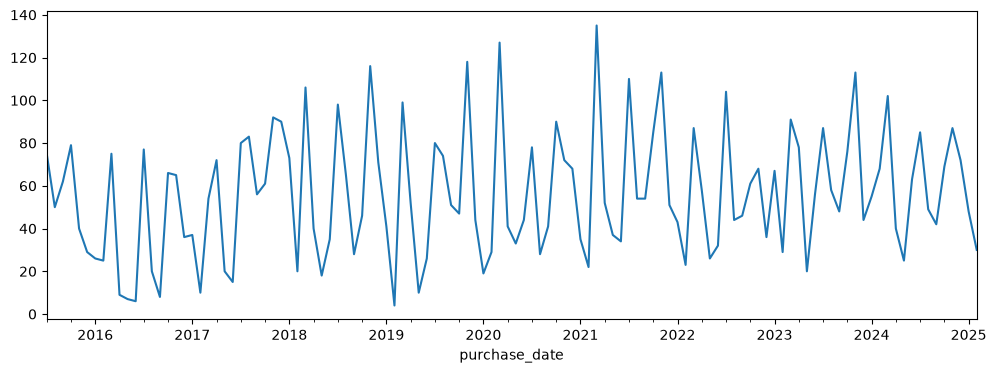

In [17]:
# Nº compras por mês
# 'ME' - it sets up the date for the end of the month
train.set_index('purchase_date').resample('ME').size().plot(figsize=(12, 4))

In [18]:
# x% das compras de cada mês tiveram recompra em 90 dias
for parte in [train['purchase_date'].dt.month]:
    print(train.groupby(parte)['repeat_purchase_90d'].mean(), "\n")

purchase_date
1.000    0.689
2.000    0.619
3.000    0.438
4.000    0.511
5.000    0.724
6.000    0.605
7.000    0.489
8.000    0.610
9.000    0.693
10.000   0.637
11.000   0.468
12.000   0.588
Name: repeat_purchase_90d, dtype: float64 



In [19]:
# taxa global
train['repeat_purchase_90d'].mean()

np.float64(0.559228650137741)

In [20]:
train['repeat_purchase_90d'].value_counts()

repeat_purchase_90d
1    3654
0    2880
Name: count, dtype: int64

C:\Users\matia\AppData\Local\Temp\ipykernel_15240\749954523.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No repeat purchase (0)", "Repeat purchase (1)"])


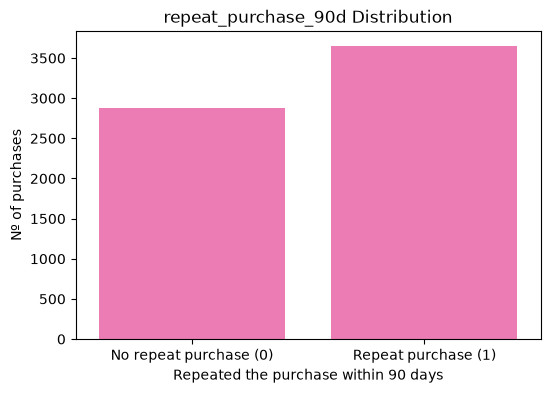

In [21]:
fig, ax = plt.subplots (figsize = (6, 4))
sns.countplot(x = "repeat_purchase_90d", data = train, ax = ax, color = "hotpink")


ax.set_xticklabels(["No repeat purchase (0)", "Repeat purchase (1)"])
ax.set_xlabel("Repeated the purchase within 90 days")
ax.set_ylabel("Nº of purchases")
ax.set_title("repeat_purchase_90d Distribution")

plt.show()

# Univariada

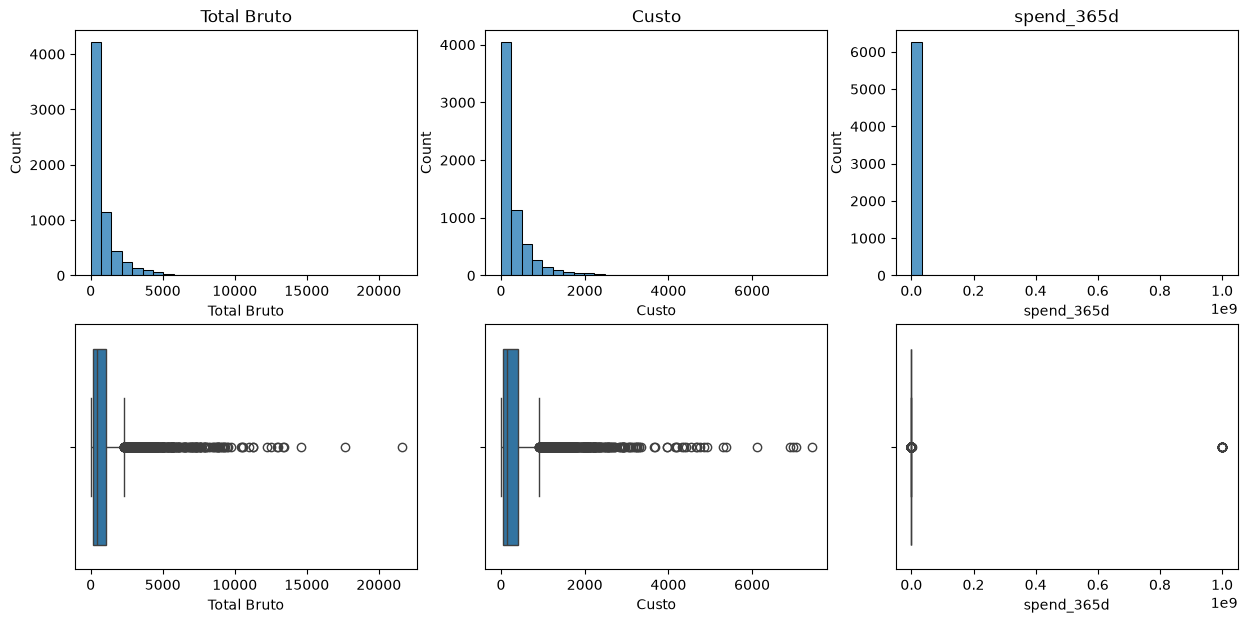

In [22]:
# Numeric features - histogram + boxplot
main_num = ["Total Bruto", "Custo", "spend_365d"]
fig, axes = plt.subplots(2, 3, figsize = (15, 7))
for i, col in enumerate(main_num):
    sns.histplot(train[col], bins = 30, ax = axes[0, i]).set_title(col)
    sns.boxplot(x = train[col], ax = axes[1, i])
plt.show()

# Multivariada

In [23]:
# To exclude features that carry no significant correlation:
cols = [c for c in num_cols if c not in ["ID", "customer_id"]]

corr = train[cols].corr(method = "spearman")
corr

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,random_noise
Total a Pagar,1.000,0.991,1.000,0.873,-0.192,-0.024,0.368,0.806,0.699,0.138,...,-0.012,-0.269,-0.213,-0.198,-0.081,-0.084,0.145,0.004,0.245,0.023
Total Bruto,0.991,1.000,0.991,0.849,-0.172,-0.019,0.459,0.788,0.698,0.143,...,-0.038,-0.233,-0.184,-0.157,-0.050,-0.050,0.169,0.036,0.267,0.021
Total Liquido,1.000,0.991,1.000,0.862,-0.193,-0.025,0.368,0.803,0.697,0.136,...,-0.009,-0.271,-0.214,-0.200,-0.082,-0.088,0.144,0.000,0.244,0.023
Total Imp_,0.873,0.849,0.862,1.000,-0.159,-0.015,0.261,0.714,0.615,0.152,...,-0.068,-0.214,-0.163,-0.143,-0.052,-0.019,0.153,0.071,0.235,0.020
Total Portes,-0.192,-0.172,-0.193,-0.159,1.000,0.083,0.066,-0.247,-0.142,0.061,...,-0.032,0.048,0.044,0.066,0.043,-0.015,-0.064,-0.050,-0.094,-0.018
Total Desc_ Global,-0.024,-0.019,-0.025,-0.015,0.083,1.000,0.009,-0.036,-0.007,0.015,...,0.102,-0.056,-0.056,-0.064,-0.071,-0.096,-0.107,-0.112,-0.120,-0.019
Total Desc_ Linha,0.368,0.459,0.368,0.261,0.066,0.009,1.000,0.313,0.379,0.078,...,-0.129,0.048,0.027,0.119,0.098,0.148,0.162,0.182,0.202,0.003
Custo,0.806,0.788,0.803,0.714,-0.247,-0.036,0.313,1.000,0.752,0.095,...,0.027,-0.246,-0.196,-0.227,-0.135,-0.108,0.069,-0.038,0.152,0.026
N_ Detalhes,0.699,0.698,0.697,0.615,-0.142,-0.007,0.379,0.752,1.000,0.113,...,0.032,-0.235,-0.203,-0.254,-0.204,-0.143,-0.026,-0.073,0.048,0.017
invoice_count_current_purchase,0.138,0.143,0.136,0.152,0.061,0.015,0.078,0.095,0.113,1.000,...,-0.083,0.043,0.046,0.063,0.075,0.082,0.104,0.097,0.115,0.012


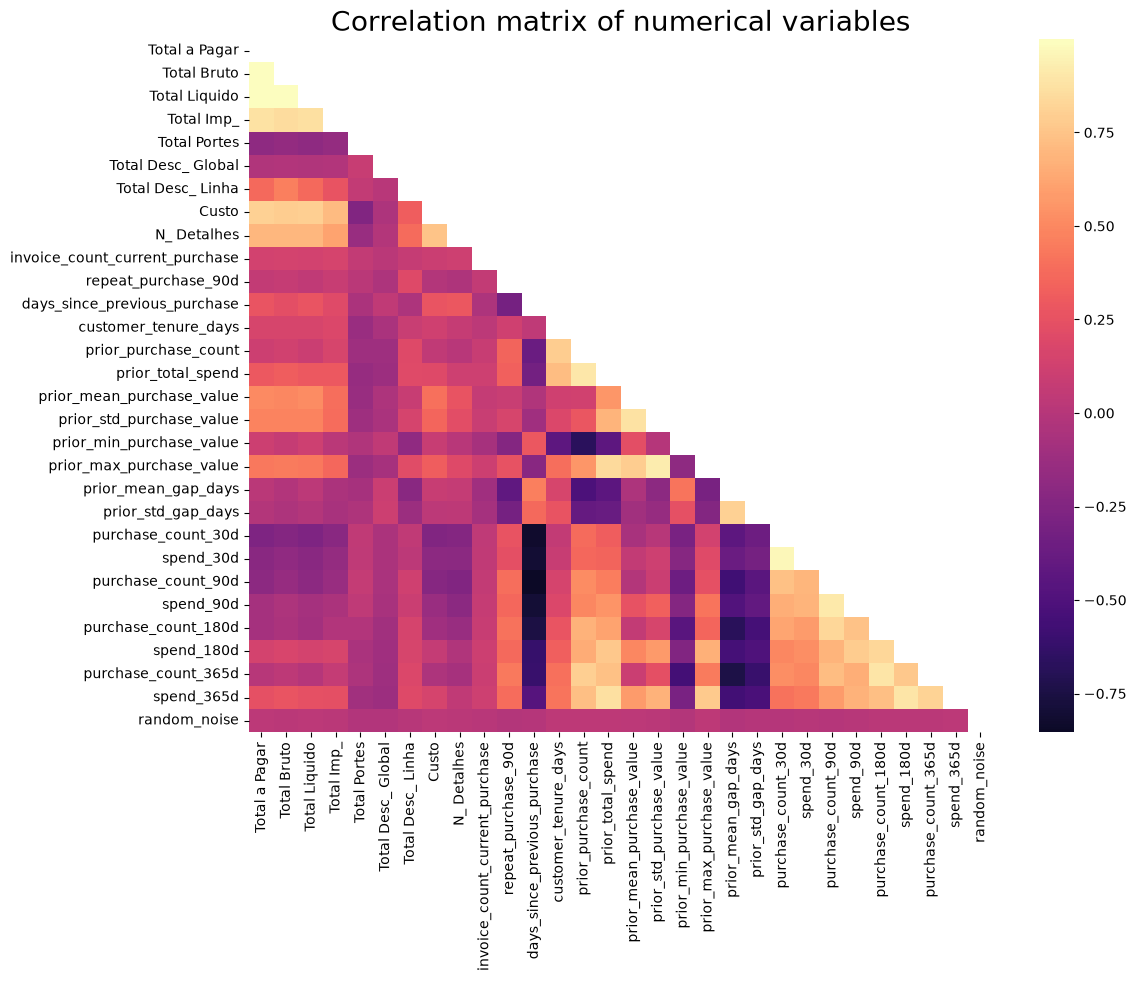

In [24]:
fig, ax = plt.subplots (figsize = (12, 9))

# To hide the upper triangle (symmetric to the lower one):
hide = np.triu(np.ones_like(corr, dtype = bool))

sns.heatmap(corr, mask = hide, cmap='magma', center = 0, annot = False)

ax.set_title("Correlation matrix of numerical variables", fontsize = 20)
plt.show()

#### Conclusions:
##### - Most variables show weak or no correlation with each other. They carry mostly independent information.
##### - All correlations with 'repeat_purchase_90d' are weak. Therefore, no single variable is able to predict correctly this feature by itself.

In [25]:
train[num_cols].corr()['repeat_purchase_90d'].sort_values()

prior_mean_gap_days              -0.238
prior_std_gap_days               -0.205
days_since_previous_purchase     -0.196
customer_id                      -0.112
prior_min_purchase_value         -0.099
random_noise                     -0.012
Total Desc_ Global               -0.012
Total Portes                     -0.001
prior_mean_purchase_value         0.005
spend_365d                        0.011
N_ Detalhes                       0.023
Custo                             0.048
invoice_count_current_purchase    0.049
Total Liquido                     0.073
Total a Pagar                     0.078
Total Bruto                       0.082
Total Desc_ Linha                 0.092
Total Imp_                        0.093
prior_max_purchase_value          0.100
customer_tenure_days              0.106
prior_std_purchase_value          0.134
spend_30d                         0.165
prior_total_spend                 0.262
purchase_count_30d                0.263
spend_90d                         0.269


## 2. Clean and Pre-Process the Data

### 2.1 Empty rows and Duplicates

In [26]:
# To find the rows where every predictor is missing:
predictors = [col for col in test.columns if col != "customer_id"]

empty_rows = train[predictors].isna().all(axis = 1)
print("Rows missing:", empty_rows.sum())

Rows missing: 65


In [27]:
# To drop the empty rows:
train = train[~empty_rows]

# To check for repeated rows:
duplicated_rows = train.duplicated()
print("Duplicated rows:", duplicated_rows.sum())

# To drop the duplicated rows:
train = train[~duplicated_rows]

# To check if the train is clean:
print("Train shape after theese drops:", train.shape)

Duplicated rows: 0
Train shape after theese drops: (6469, 38)


In part 1 we found that there were 10 duplicated rows, but all of them made part of the empty rows. Therefore, we dropped them.

Once they were dropped, no duplicates are left!

### 2.2 Dates

In [28]:
# The test dataset writes the dates in a different format from the train dataset, so we have to convert them:

test["purchase_date"] = pd.to_datetime(test["purchase_date"], format = "%Y-%m-%d")

print("Train:", train["purchase_date"].min().date(), "to", train["purchase_date"].max().date())
print("Test:", test["purchase_date"].min().date(), "to", test["purchase_date"].max().date())

Train: 2015-07-11 to 2025-02-15
Test: 2025-05-24 to 2026-10-06


### 2.3 Impossible values

We have to check the maximum values of the single purchases made by each customer:

In [29]:
print(train["prior_mean_purchase_value"].sort_values(ascending=False).head(20))

ID
10006001   1,000,000,000.000
10007471   1,000,000,000.000
10003702   1,000,000,000.000
10006049   1,000,000,000.000
10003106   1,000,000,000.000
10007199   1,000,000,000.000
10005563   1,000,000,000.000
10002792   1,000,000,000.000
10007157   1,000,000,000.000
10002865   1,000,000,000.000
10000226   1,000,000,000.000
10006668   1,000,000,000.000
10000304   1,000,000,000.000
10006258   1,000,000,000.000
10001890   1,000,000,000.000
10004113   1,000,000,000.000
10002779          72,937.163
10001317          30,448.603
10001369          27,763.495
10007108          24,706.130
Name: prior_mean_purchase_value, dtype: float64


In [30]:
#Count the impossible values of the dataset

def count_impossible(df):
    return pd.Series({
        "prior_mean_purchase_value= 1e9":(df["prior_mean_purchase_value"]>= 1e9).sum(),
        "prior_mean_purchase_value< 0":(df["prior_mean_purchase_value"]< 0).sum(),
        "spend_365d =1e9":(df["spend_365d"]>= 1e9).sum(),
        "spend_365d< 0":(df["spend_365d"]< 0).sum(),
        "days_since_previous_purchase< 0":(df["days_since_previous_purchase"]< 0).sum(),
        "prior_mean_gap_days< 0":(df["prior_mean_gap_days"]< 0).sum(),
    })

pd.DataFrame({"train": count_impossible(train), "test":count_impossible(test)})

,train,test
prior_mean_purchase_value= 1e9,16,2
prior_mean_purchase_value< 0,16,2
spend_365d =1e9,15,2
spend_365d< 0,15,2
days_since_previous_purchase< 0,16,2
prior_mean_gap_days< 0,16,2


In [31]:
# Instead of throw away the impossibe values, lets check if the average purchase value can be recomputed:

if_valid = (train["prior_mean_purchase_value"] > 0) & (train["prior_mean_purchase_value"] < 1e9)
recomputed = train["prior_total_spend"] / train["prior_purchase_count"]

same = np.isclose(recomputed[if_valid], train.loc[if_valid, "prior_mean_purchase_value"], rtol=0.001)
print(f"% in which valid rows can be recomputed (by the mean): {same.mean():.1%}")

% in which valid rows can be recomputed (by the mean): 99.2%


In [32]:
# Now, lets fix the impossible values:
def fix_impossible_values(df):
    df = df.copy()

    # The mean is wrong when the prior mean purchase value is higher than 1e9 or lower then 0
    wrong_mean = (df["prior_mean_purchase_value"] >= 1e9)| (df["prior_mean_purchase_value"] < 0)
    df.loc[wrong_mean, "prior_mean_purchase_value"] = (
        df.loc[wrong_mean, "prior_total_spend"] / df.loc[wrong_mean, "prior_purchase_count"]
    )
    # To chnage the wrong mean value to the mean value of total spends/prior purchases

    # The spend is wrong when its value is higher than 1e9 or lower then 0, of the 365 days
    wrong_spend = (df["spend_365d"] >= 1e9) | (df["spend_365d"] < 0)
    df.loc[wrong_spend, "spend_365d"] = np.nan

    # Since days cannot be negative, we put the -4 values as nan:
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        df.loc[df[col] < 0, col] = np.nan

    return df


train = fix_impossible_values(train)
test = fix_impossible_values(test)

pd.DataFrame({"train": count_impossible(train), "test": count_impossible(test)})

,train,test
prior_mean_purchase_value= 1e9,0,0
prior_mean_purchase_value< 0,0,0
spend_365d =1e9,0,0
spend_365d< 0,0,0
days_since_previous_purchase< 0,0,0
prior_mean_gap_days< 0,0,0


In [33]:
# When prior purchase = 0, we have a new customer
for df in [train, test]:
    df["is_first_purchase"] = (df["prior_purchase_count"] == 0).astype(int)

train["is_first_purchase"].value_counts()

is_first_purchase
0    5866
1     603
Name: count, dtype: int64

There are 603 customers that correspond to new ones

### 2.4 Integration of clientes.csv

In [34]:
# Check clientes content:

print("Every train customer is in clientes:", train["customer_id"].isin(clientes["customer_id"]).all())
print("Every test customer is in clientes: ", test["customer_id"].isin(clientes["customer_id"]).all())
print("Repeated customers in clientes:", clientes["customer_id"].duplicated().sum())
print()

print("Total number of customers:",clientes["customer_id"].shape)
print() 

# Missing values:
print("Missing values:\n", (clientes.isna().sum()).round(1).sort_values(ascending=False))

Every train customer is in clientes: True
Every test customer is in clientes:  True
Repeated customers in clientes: 0

Total number of customers: (1143,)

Missing values:
 customer_type          1143
street                  598
island                  578
city                    546
postal_code             170
municipality            159
commercial_region       114
postal_area              71
address                   6
country_or_region         0
customer_id               0
company_name              0
customer_since_year       0
dtype: int64


- customer_type is 100% empty, so it has no use.
- street, address, postal_code, city, company_name only identify the customer instead of describing it, and many are empty.
- customer_since_year is 2015 for most customers, the year the data starts, so it means "2015 or earlier".
- customer_tenure_days (train) already gives the same information.
- Then, we conclude that commercial_region and country_or_region are the columns worth testing!

In [35]:
clientes_2 = clientes[["customer_id", "commercial_region", "country_or_region"]]

# join() keeps the ID index of train and test 
train = train.join(clientes_2.set_index("customer_id"), on="customer_id")
test = test.join(clientes_2.set_index("customer_id"), on="customer_id")

(train.groupby("commercial_region")["repeat_purchase_90d"]
      .agg(["mean", "size"])
      .sort_values("size", ascending = False)
      .head(8)
      .round(3))

,mean,size
commercial_region,,
Region RG17: We Will See Later,0.519,4069
Region RG23: We Will See Later,0.827,560
Region RG18: We Will See Later,0.621,364
Region RG24: We Will See Later,0.944,232
Region RG29: We Will See Later,0.507,211
Region RG27: We Will See Later,0.646,192
Region RG31: We Will See Later,0.460,163
Region RG28: We Will See Later,0.437,119


- The regions behave very differently. This information shows us that it is important to use clientes.csv, because the mean varies from 44% to 94%
- This is information the train dataset doesn't have, so commercial_region will be kept!

### 2.5 New Features

In [36]:
def add_features(df):
    df = df.copy()
    df["discount_share"] = df["Total Desc_ Linha"] / df["Total Bruto"]
    df["margin_share"] = (df["Total Liquido"] - df["Custo"]) / df["Total Liquido"]
    df["value_per_detail"] = df["Total Liquido"] / df["N_ Detalhes"]
    df["overdue_ratio"] = df["days_since_previous_purchase"] / df["prior_mean_gap_days"]
    df["purchase_month"] = df["purchase_date"].dt.month.astype(str)   # a category, not a numeric variable
    return df


train = add_features(train)
test = add_features(test)

# A division by zero gives infinity, so we turn those values in nan 
train = train.replace([np.inf, -np.inf], np.nan)
test = test.replace([np.inf, -np.inf], np.nan)

| new feature | formula | idea |
|---|---|---|
| discount_share | line discount / gross total | how much of the purchase was discounted |
| margin_share | (net total - cost) / net total | how profitable the purchase was |
| value_per_detail | net total / number of details | average value of each line |
| overdue_ratio | days since previous purchase / usual gap | > 1 means the customer came back later than usual |
| purchase_month | month of purchase_date | seasonality |

### 2.6 Training and Validation Split

- Since `test.csv` is in the future, we keep the **most recent 20%** of train as **validation** and use the **oldest 80%** for **training**

In [37]:
# Let's start by sort by date and then split
train = train.sort_values("purchase_date")

cut = int(len(train) * 0.8)
train_part = train.iloc[:cut]
val_part = train.iloc[cut:]

print("Training:  ", train_part["purchase_date"].min().date(), "to", train_part["purchase_date"].max().date(), "|", len(train_part), "rows")
print("Validation:", val_part["purchase_date"].min().date(), "to", val_part["purchase_date"].max().date(), "|", len(val_part), "rows")

Training:   2015-07-11 to 2023-06-17 | 5175 rows
Validation: 2023-06-17 to 2025-02-15 | 1294 rows


In [38]:
# Separate the target and remove the columns that will not be features:
## X - what the model uses to learn
## y - what the model uses to answer

target = "repeat_purchase_90d"
not_features = [target, "customer_id", "purchase_date"]

X_train = train_part.drop(columns=not_features)
y_train = train_part[target]

X_val = val_part.drop(columns=not_features)
y_val = val_part[target]

X_test = test.drop(columns=["customer_id", "purchase_date"])

print(X_train.shape, X_val.shape, X_test.shape)

(5175, 43) (1294, 43) (986, 43)


In [39]:
# Sort the columns in 3 groups, because each one will be treated differently

# Categorical column:
cat_cols = ["payment_type", "salesperson", "commercial_zone", "transport_method",
            "warehouse", "document_series", "commercial_region", "country_or_region", "purchase_month"]

# First Purchases column (new customers):
binary_cols = ["is_first_purchase"]

# Numeric column:
num_cols = [col for col in X_train.columns if col not in cat_cols + binary_cols]

# In strongly right-skewed columns (skew > 1) with no negative values, we have to put a log 
## The skew must be measured on the training rows only
skew = X_train[num_cols].skew()
log_cols = [col for col in num_cols if skew[col] > 1 and X_train[col].min() >= 0]
other_num_cols = [col for col in num_cols if col not in log_cols]

print("Log + scale:", len(log_cols), "columns")
print("Scale only: ", other_num_cols)

Log + scale: 30 columns
Scale only:  ['customer_tenure_days', 'random_noise', 'margin_share']


In [40]:
# Build the preprocessor with one pipeline for each group

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

log_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])

num_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist",
                             sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("log", log_pipeline, log_cols),
    ("num", num_pipeline, other_num_cols),
    ("cat", cat_pipeline, cat_cols),
    ("binary", "passthrough", binary_cols),
])

# Return DataFrames with column names instead of plain arrays:
preprocessor = preprocessor.set_output(transform="pandas")

In [41]:
# Put the rules and what it's learned into rolling, to understand if there is valid transformation and testing

# The model will learn categories, means, standard deviations and medians:
X_train_prep = preprocessor.fit_transform(X_train)

# The model will only apply what it learned:
X_val_prep = preprocessor.transform(X_val)    

X_test_prep = preprocessor.transform(X_test)

print("Shapes:", X_train_prep.shape, X_val_prep.shape, X_test_prep.shape)
print("Missing values left:", X_train_prep.isna().sum().sum(), X_val_prep.isna().sum().sum(), X_test_prep.isna().sum().sum())

Shapes: (5175, 111) (1294, 111) (986, 111)
Missing values left: 0 0 0


In [45]:
# Example that shows that the training columns now have mean 0 and standard deviation 1
X_train_prep[["log__Total a Pagar", "log__purchase_count_365d", "num__customer_tenure_days"]].describe().round(2)

,log__Total a Pagar,log__purchase_count_365d,num__customer_tenure_days
count,"5,175.000","5,175.000","5,175.000"
mean,0.000,-0.000,0.000
std,1.000,1.000,1.000
min,-3.940,-1.520,-1.190
25%,-0.610,-0.810,-0.870
50%,0.080,-0.100,-0.190
75%,0.690,0.600,0.740
max,2.650,2.670,2.660
